In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
from sklearn.datasets import make_blobs

# 1. Generate a dataset with 20 points and 2 features

In [17]:
X, _ = make_blobs(
    n_samples=20,
    centers=3,
    n_features=2,
    cluster_std=1.0,
    random_state=42
)

df = pd.DataFrame(X, columns=["X", "Y"])

In [18]:
print("Dataset:")
print(df.round(2).to_string(index=False))

Dataset:
    X     Y
-2.98  9.56
-4.23  8.45
-3.52  9.33
-2.27  7.10
 3.49  2.35
-8.21 -6.68
-2.97  8.55
 4.63  0.92
 4.10  2.08
 4.04  1.68
-6.67 -8.84
 6.11  1.75
-6.14 -6.71
-3.42  7.60
-7.00 -7.18
-0.93  9.78
-8.36 -7.60
-6.06 -8.10
 4.71  0.55
 4.04  3.83


# 2. Visualize the original dataset

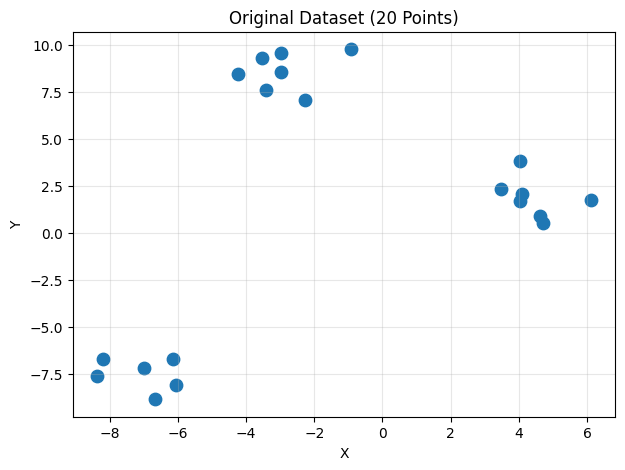

In [19]:
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=80)
plt.title("Original Dataset (20 Points)")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(alpha=0.3)
plt.show()

# 3. Apply K-Means for different K values

K =  1, SSE = 1323.8033


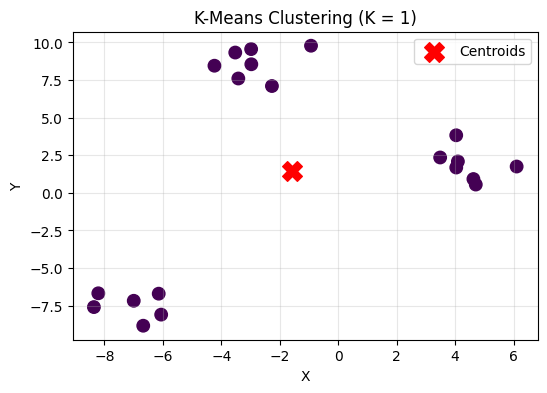

K =  2, SSE = 380.5750


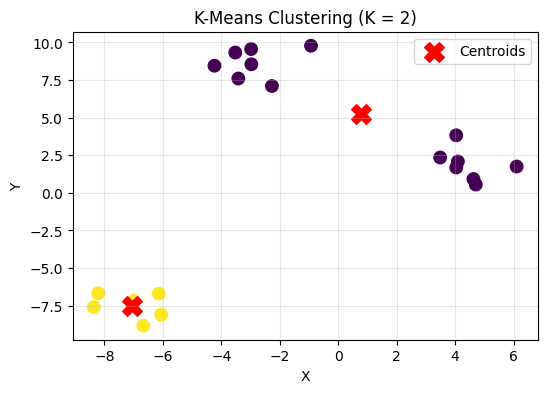

K =  3, SSE = 32.4319


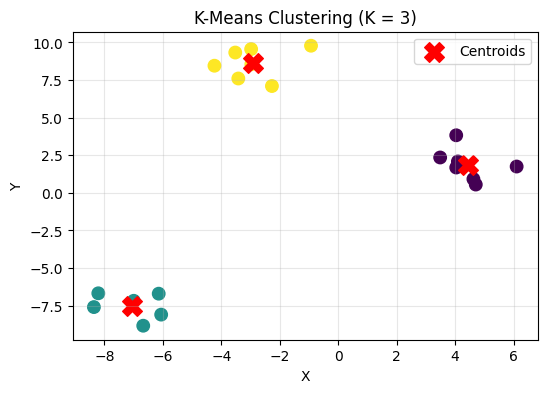

K =  4, SSE = 26.3270


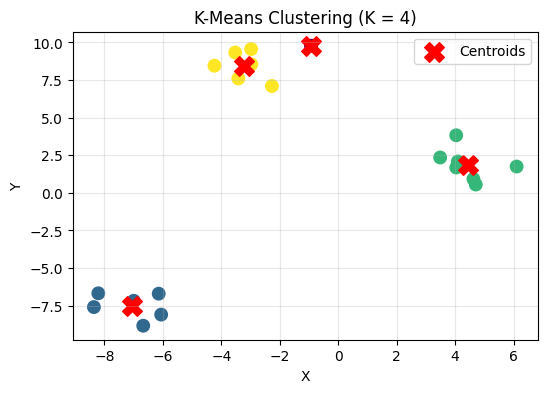

K =  5, SSE = 21.8570


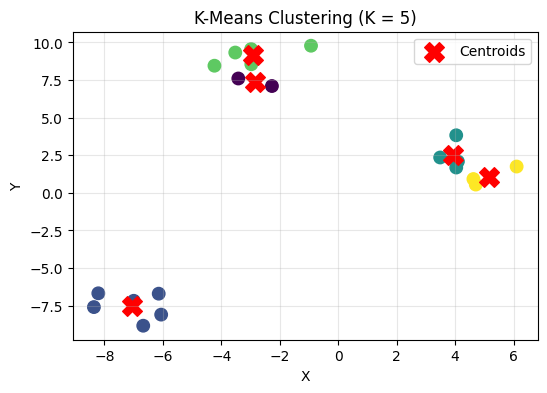

K =  6, SSE = 16.0809


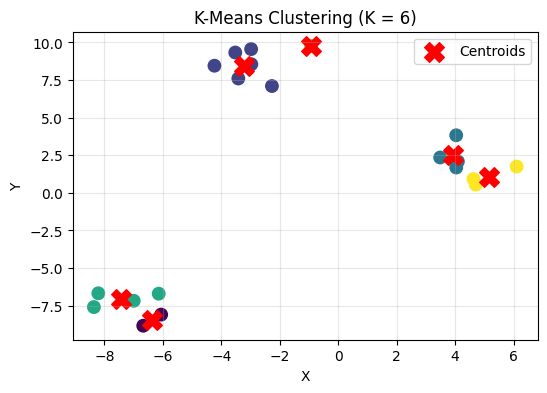

K =  7, SSE = 12.1618


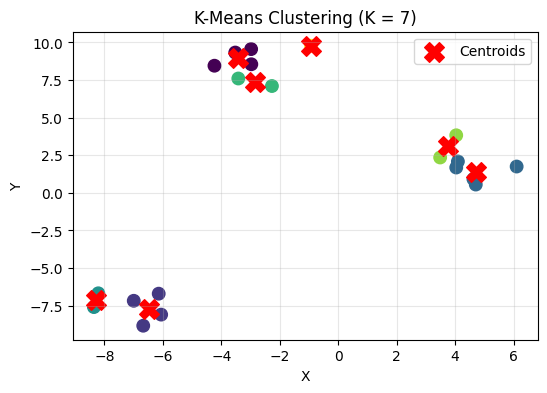

K =  8, SSE = 9.0995


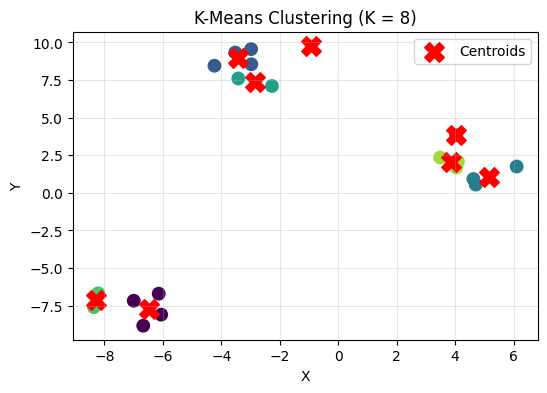

K =  9, SSE = 7.4448


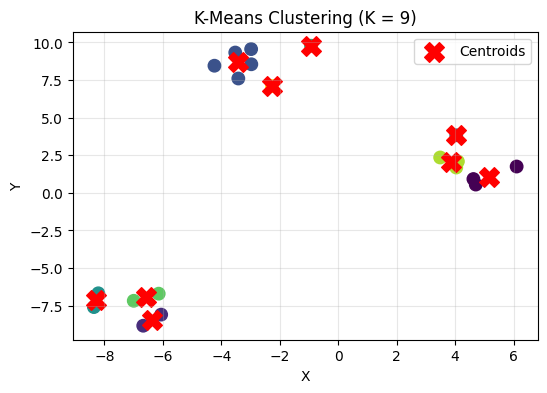

K = 10, SSE = 4.6638


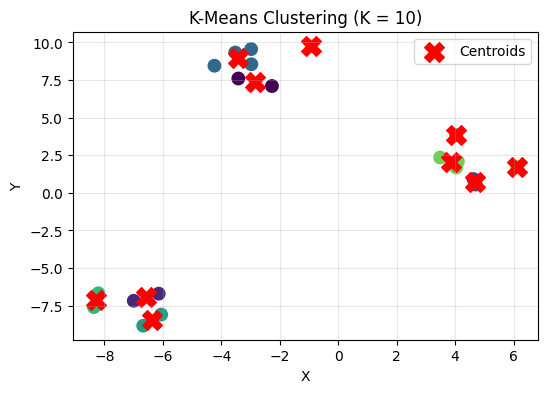

K = 11, SSE = 3.3433


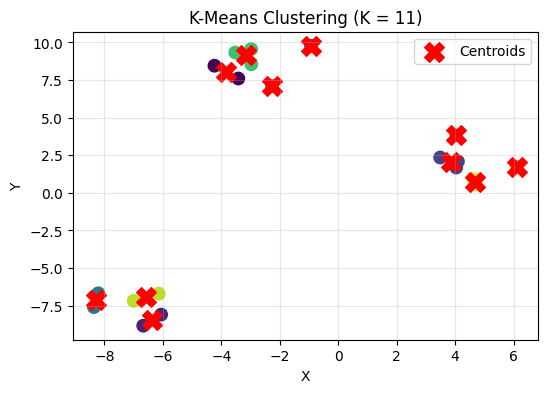

K = 12, SSE = 2.6108


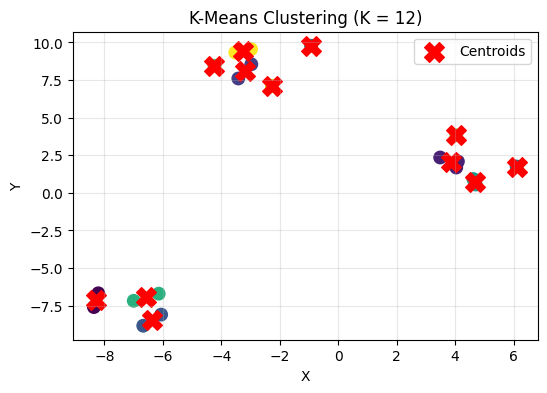

K = 13, SSE = 2.0640


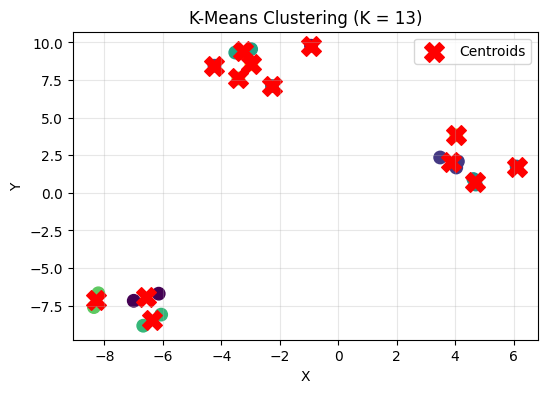

K = 14, SSE = 1.5876


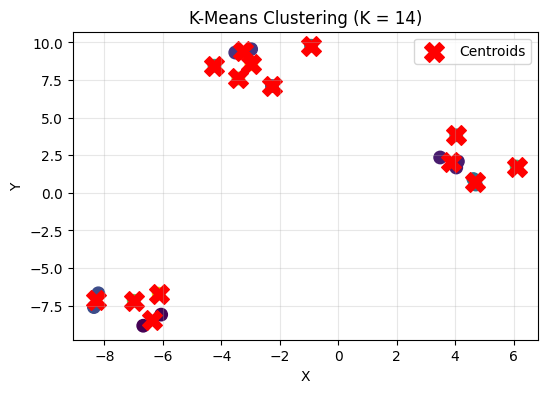

K = 15, SSE = 1.1263


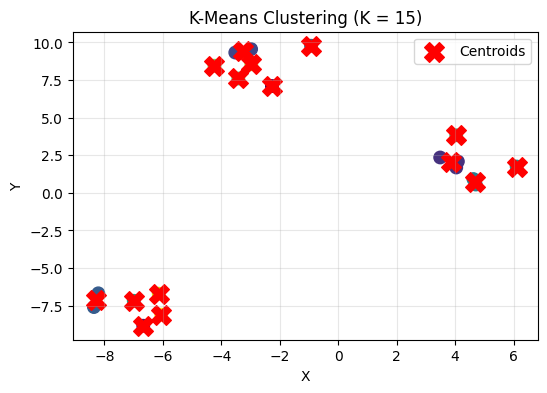

K = 16, SSE = 0.6949


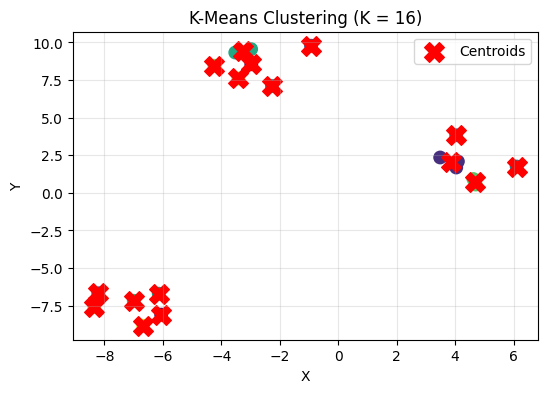

K = 17, SSE = 0.3270


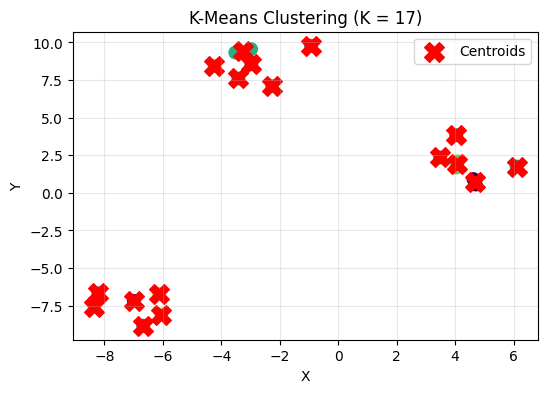

K = 18, SSE = 0.1533


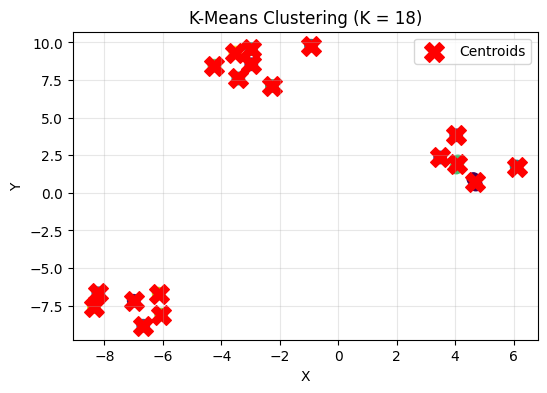

K = 19, SSE = 0.0706


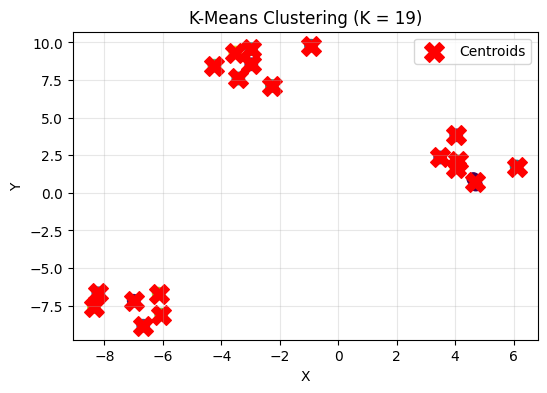

K = 20, SSE = 0.0000


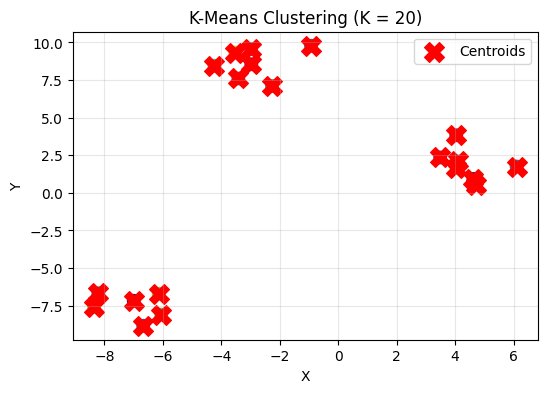

In [28]:
sse_values = []

for k in range(1, 21):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    # SSE = sum of squared distances to nearest centroid
    sse = kmeans.inertia_
    sse_values.append(sse)

    print(f"K = {k:2d}, SSE = {sse:.4f}")

    # Visualize clustering for each K
    plt.figure(figsize=(6, 4))

    plt.scatter(
        X[:, 0], X[:, 1],
        c=kmeans.labels_,
        cmap="viridis",
        s=80
    )

    plt.scatter(
        kmeans.cluster_centers_[:, 0],
        kmeans.cluster_centers_[:, 1],
        marker="X",
        c="red",
        s=200,
        label="Centroids"
    )

    plt.title(f"K-Means Clustering (K = {k})")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


# 4. Plot the Elbow Curve

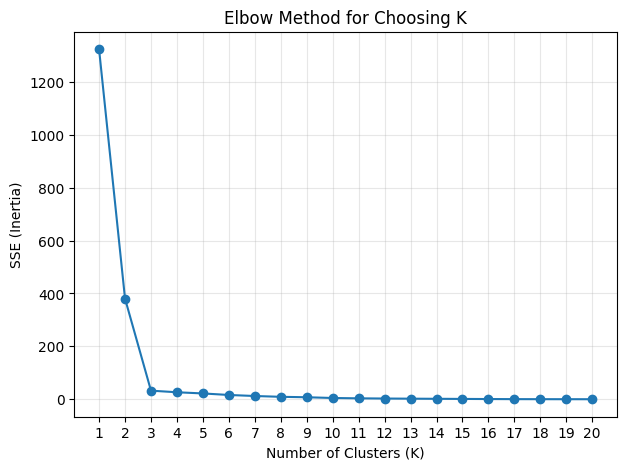

In [26]:
plt.figure(figsize=(7, 5))
plt.plot(
    range(1, 21),
    sse_values,
    marker="o"
)
plt.xticks(range(1, 21))
plt.xlabel("Number of Clusters (K)")
plt.ylabel("SSE (Inertia)")
plt.title("Elbow Method for Choosing K")
plt.grid(alpha=0.3)
plt.show()

# 5. Display SSE table

In [23]:
results = pd.DataFrame({
    "K": range(1, 21),
    "SSE": sse_values
})

In [24]:
print("\nSSE Table:")
print(results.round(4).to_string(index=False))


SSE Table:
 K       SSE
 1 1323.8033
 2  380.5750
 3   32.4319
 4   26.3270
 5   21.8570
 6   16.0809
 7   12.1618
 8    9.0995
 9    7.4448
10    4.6638
11    3.3433
12    2.6108
13    2.0640
14    1.5876
15    1.1263
16    0.6949
17    0.3270
18    0.1533
19    0.0706
20    0.0000
